In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load cleaned dataset
df = pd.read_csv("data/processed/cleaned_data.csv")

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (100000, 42)


,record_id,product_id,product_name,category,store_id,region,supplier_id,transaction_date,expiration_date,shelf_life_days,...,selling_price,units_sold,units_wasted,waste_pct,revenue,waste_cost,profit,profit_margin_pct,supplier_score,is_promoted
0,1,BAK_DON_743,Donuts,Bakery,STORE_046,West,SUPPLIER_03,2024-09-25,2024-09-29,4,...,2.60,138,20,12.7,358.80,24.40,166.04,46.3,9,0
1,2,MEA_SAU_338,Sausages,Meat,STORE_030,Southwest,SUPPLIER_12,2023-04-14,2023-04-21,9,...,8.25,251,102,28.9,2070.75,426.36,595.21,28.7,6,0
2,3,BAK_BAG_799,Bagels,Bakery,STORE_035,Midwest,SUPPLIER_08,2024-10-25,2024-10-27,2,...,1.28,483,0,0.0,618.24,0.00,-405.72,-65.6,9,0
3,4,PHA_VAC_801,Vaccines,Pharmaceuticals,STORE_003,Midwest,SUPPLIER_11,2023-11-29,2024-02-17,87,...,209.56,477,0,0.0,99960.12,0.00,57988.89,58.0,6,0
4,5,REA_FRE_422,Fresh Pasta,Ready_to_Eat,STORE_042,West,SUPPLIER_15,2023-08-06,2023-08-09,4,...,5.28,391,0,0.0,2064.48,0.00,879.75,42.6,6,0


In [2]:
pca_features = [
    "shelf_life_days",
    "days_remaining_at_purchase",
    "storage_temp",
    "temp_deviation",
    "base_price",
    "cost_price",
    "initial_quantity",
    "spoilage_sensitivity",
    "day_of_week",
    "is_weekend",
    "month",
    "demand_variability",
    "temp_abuse_events",
    "distribution_hours",
    "handling_score",
    "packaging_score",
    "spoilage_risk",
    "days_until_expiry",
    "markdown_applied",
    "discount_pct",
    "supplier_score",
    "is_promoted"
]

X = df[pca_features].copy()

print("PCA input shape:", X.shape)
print("Number of features:", len(pca_features))

PCA input shape: (100000, 22)
Number of features: 22


In [4]:
%pip install scikit-learn

  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ------- -------------------------------- 1.6/8.4 MB 8.2 MB/s eta 0:00:01
   ------------------ --------------------- 3.9/8.4 MB 10.1 MB/s eta 0:00:01
   ------------------------------- -------- 6.6/8.4 MB 10.9 MB/s eta 0:00:01
   -------------------------------------- - 8.1/8.4 MB 10.4 MB/s eta 0:00:01
   ---------------------------------------- 8.4/8.4 MB 9.7 MB/s  0:00:00
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   - -------------------------------------- 1.8/37.4 MB 9.8 MB/s eta 0:00:04
   --- ------------------------------------ 3.4/37.4 MB 8.1 MB/s eta 0:00:05
   ----- ---------------------------------- 5.0/37.4 MB 7.7 MB/s eta 0:00:05
   ------ --------------------------------- 5.8/37.4 MB 7.3 MB/s eta 0:00:05
   ------- -------------------------------- 7.1/3


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
from sklearn.preprocessing import StandardScaler

# Initialize scaler
scaler = StandardScaler()

# Standardize the selected features
X_scaled = scaler.fit_transform(X)

# Convert back to DataFrame for inspection
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=pca_features
)

print("Scaled dataset shape:", X_scaled_df.shape)

print("\nFeature means after scaling:")
print(X_scaled_df.mean().round(3))

print("\nFeature standard deviations after scaling:")
print(X_scaled_df.std().round(3))

Scaled dataset shape: (100000, 22)

Feature means after scaling:
shelf_life_days              -0.0
days_remaining_at_purchase    0.0
storage_temp                 -0.0
temp_deviation               -0.0
base_price                   -0.0
cost_price                    0.0
initial_quantity              0.0
spoilage_sensitivity         -0.0
day_of_week                  -0.0
is_weekend                    0.0
month                         0.0
demand_variability           -0.0
temp_abuse_events             0.0
distribution_hours           -0.0
handling_score                0.0
packaging_score               0.0
spoilage_risk                -0.0
days_until_expiry             0.0
markdown_applied             -0.0
discount_pct                  0.0
supplier_score               -0.0
is_promoted                   0.0
dtype: float64

Feature standard deviations after scaling:
shelf_life_days               1.0
days_remaining_at_purchase    1.0
storage_temp                  1.0
temp_deviation            

In [6]:
from sklearn.decomposition import PCA

# Initialize PCA
pca = PCA()

# Fit PCA on standardized data
X_pca = pca.fit_transform(X_scaled)

print("PCA transformed shape:", X_pca.shape)

print("\nExplained variance ratio:")
print(pca.explained_variance_ratio_)

print("\nExplained variance percentage:")
print(pca.explained_variance_ratio_ * 100)

PCA transformed shape: (100000, 22)

Explained variance ratio:
[1.93805876e-01 1.18542524e-01 8.14754725e-02 7.54104795e-02
 6.64108991e-02 5.27795820e-02 4.59877427e-02 4.56224813e-02
 4.55293510e-02 4.54838856e-02 4.51341177e-02 4.51006888e-02
 4.14676223e-02 3.46087426e-02 2.23255631e-02 2.02333704e-02
 9.48757467e-03 6.50539218e-03 2.99312838e-03 6.31692301e-04
 4.62054390e-04 1.75976432e-06]

Explained variance percentage:
[1.93805876e+01 1.18542524e+01 8.14754725e+00 7.54104795e+00
 6.64108991e+00 5.27795820e+00 4.59877427e+00 4.56224813e+00
 4.55293510e+00 4.54838856e+00 4.51341177e+00 4.51006888e+00
 4.14676223e+00 3.46087426e+00 2.23255631e+00 2.02333704e+00
 9.48757467e-01 6.50539218e-01 2.99312838e-01 6.31692301e-02
 4.62054390e-02 1.75976432e-04]


In [7]:
# Calculate cumulative explained variance
cumulative_variance = np.cumsum(
    pca.explained_variance_ratio_
)

# Display results
pca_results = pd.DataFrame({
    "Principal Component": [
        f"PC{i+1}" for i in range(len(cumulative_variance))
    ],
    "Individual Variance (%)":
        pca.explained_variance_ratio_ * 100,
    "Cumulative Variance (%)":
        cumulative_variance * 100
})

display(pca_results.round(2))

# Number of components required
pc_90 = np.argmax(cumulative_variance >= 0.90) + 1
pc_95 = np.argmax(cumulative_variance >= 0.95) + 1

print("Components for 90% variance:", pc_90)
print("Components for 95% variance:", pc_95)

,Principal Component,Individual Variance (%),Cumulative Variance (%)
0,PC1,19.38,19.38
1,PC2,11.85,31.23
2,PC3,8.15,39.38
3,PC4,7.54,46.92
4,PC5,6.64,53.56
5,PC6,5.28,58.84
6,PC7,4.60,63.44
7,PC8,4.56,68.00
8,PC9,4.55,72.56
9,PC10,4.55,77.10


Components for 90% variance: 13
Components for 95% variance: 15


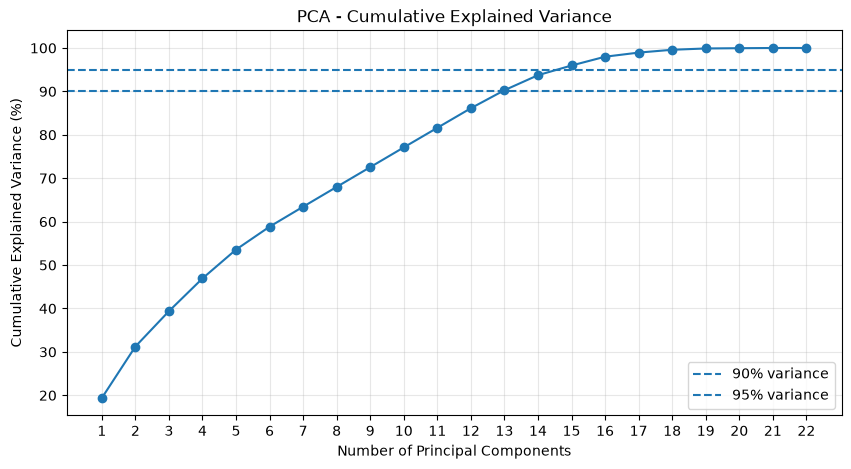

In [8]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance * 100,
    marker="o"
)

plt.axhline(
    y=90,
    linestyle="--",
    label="90% variance"
)

plt.axhline(
    y=95,
    linestyle="--",
    label="95% variance"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("PCA - Cumulative Explained Variance")

plt.xticks(range(1, 23))
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [9]:
# Extract PCA component coefficients
loadings = pd.DataFrame(
    pca.components_.T,
    index=pca_features,
    columns=[
        f"PC{i+1}" for i in range(len(pca_features))
    ]
)

# Display the five strongest contributing features
# for each of the first five components

for pc in loadings.columns[:5]:

    print(f"\nTop features contributing to {pc}")

    top_features = (
        loadings[pc]
        .abs()
        .sort_values(ascending=False)
        .head(5)
    )

    for feature in top_features.index:
        print(
            feature,
            ":", round(loadings.loc[feature, pc], 4)
        )


Top features contributing to PC1
shelf_life_days : 0.4587
days_until_expiry : 0.4587
days_remaining_at_purchase : 0.4586
base_price : 0.3939
cost_price : 0.3904

Top features contributing to PC2
spoilage_risk : 0.5205
markdown_applied : 0.4618
discount_pct : 0.4175
packaging_score : -0.3368
handling_score : -0.255

Top features contributing to PC3
is_weekend : 0.7053
day_of_week : 0.7052
temp_deviation : -0.0468
temp_abuse_events : -0.0435
markdown_applied : 0.0173

Top features contributing to PC4
temp_deviation : 0.6046
temp_abuse_events : 0.5774
spoilage_sensitivity : -0.2291
discount_pct : -0.2283
spoilage_risk : 0.2149

Top features contributing to PC5
storage_temp : 0.4857
spoilage_sensitivity : 0.4677
cost_price : 0.3055
base_price : 0.3033
temp_abuse_events : 0.2599


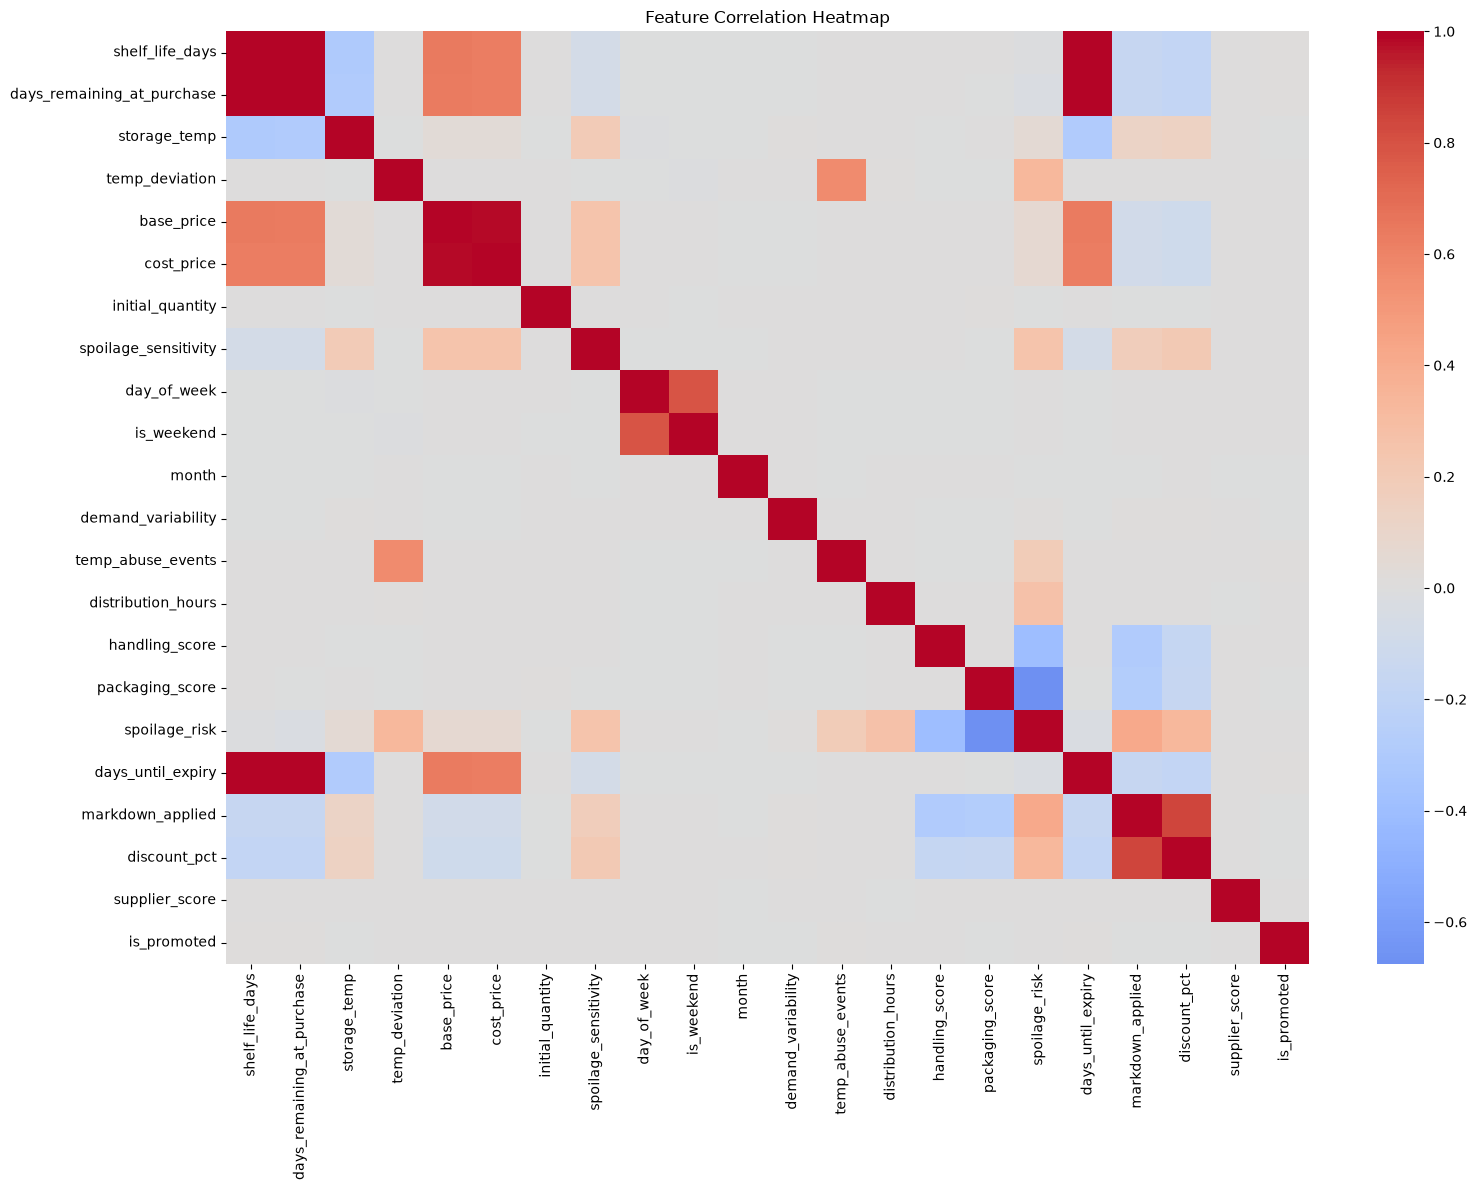

In [10]:
import seaborn as sns

# Calculate correlation matrix
correlation_matrix = X.corr()

# Plot correlation heatmap
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

In [11]:
# Identify highly correlated feature pairs
corr_pairs = (
    correlation_matrix
    .abs()
    .where(np.triu(
        np.ones(correlation_matrix.shape), k=1
    ).astype(bool))
    .stack()
    .sort_values(ascending=False)
)

print("Feature pairs with correlation above 0.80:\n")

display(corr_pairs[corr_pairs > 0.80].to_frame(
    name="Absolute Correlation"
))

Feature pairs with correlation above 0.80:



Absolute Correlation
days_remaining_at_purchase days_until_expiry                       0.999957
shelf_life_days            days_remaining_at_purchase              0.991776
                           days_until_expiry                       0.991731
base_price                 cost_price                              0.985952
markdown_applied           discount_pct                            0.846983

In [12]:
# Remove the inconsistent feature from PCA
pca_features_v2 = [
    col for col in pca_features
    if col != "days_until_expiry"
]

# Prepare updated feature matrix
X_v2 = df[pca_features_v2].copy()

print("Updated PCA input shape:", X_v2.shape)
print("Number of features:", len(pca_features_v2))

Updated PCA input shape: (100000, 21)
Number of features: 21


In [13]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

scaler_v2 = StandardScaler()

X_scaled_v2 = scaler_v2.fit_transform(X_v2)

pca_v2 = PCA()

X_pca_v2 = pca_v2.fit_transform(X_scaled_v2)

cumulative_v2 = np.cumsum(
    pca_v2.explained_variance_ratio_
)

print(
    "Components for 90% variance:",
    np.argmax(cumulative_v2 >= 0.90) + 1
)

print(
    "Components for 95% variance:",
    np.argmax(cumulative_v2 >= 0.95) + 1
)

print("Updated PCA shape:", X_pca_v2.shape)

Components for 90% variance: 13
Components for 95% variance: 15
Updated PCA shape: (100000, 21)
